# Anatomical Parameter Scans
This notebook performs parameter scans on the C4 metabolic model to analyze the impact of anatomical constraints (specifically the Bundle Sheath to Mesophyll volume ratio, $V_{BS/M}$) on metabolic fluxes under various physiological conditions.

## 1. Setup and Model Preparation
Import necessary libraries and prepare the C4 model with specific maintenance constraints.

In [1]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import pandas as pd
from cobra.io import read_sbml_model
from cobra import flux_analysis
import sys
from Auxiliary import *
import multiprocessing
import time
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Loading and Constraining the C4 Model
Load the SBML model and apply light-dependent ATP maintenance costs and ATP/NADPH ratio constraints.

In [2]:
"""
Read and prepare C4 model
"""

start = time.time()

#Import C4 model
c4_model = read_sbml_model("../Models/c4_model.xml")

#Define the solver
c4_model.solver = "gurobi"

#Set light-dependent ATP maintence costs
def c4_maintenance(c4_model):
    #Constrains for light dependent maintenance costs
    atp_b = c4_model.reactions.get_by_id("[B]_ATPase_tx")
    photon_b = c4_model.reactions.get_by_id("[B]_Photon_tx")
    atp_m = c4_model.reactions.get_by_id("[M]_ATPase_tx")
    photon_m = c4_model.reactions.get_by_id("[M]_Photon_tx")

    const_b = c4_model.problem.Constraint((0.0049 * photon_b.flux_expression + 2.7852) - atp_b.flux_expression, lb=0,
                                          ub=0)
    c4_model.add_cons_vars(const_b)

    const_m = c4_model.problem.Constraint((0.0049 * photon_m.flux_expression + 2.7852) - atp_m.flux_expression, lb=0,
                                          ub=0)
    c4_model.add_cons_vars(const_m)

    
    # ATP/NADPH 3:1 constraints (Calvin Cycle requirement)
    const = c4_model.problem.Constraint(c4_model.reactions.get_by_id("[B]_ATPase_tx").flux_expression - 3 * (
            c4_model.reactions.get_by_id("[B]_NADPHoxc_tx").flux_expression + c4_model.reactions.get_by_id(
        "[B]_NADPHoxp_tx").flux_expression + c4_model.reactions.get_by_id("[B]_NADPHoxm_tx").flux_expression), lb=0,
                                        ub=0)
    c4_model.add_cons_vars(const)

    const = c4_model.problem.Constraint(c4_model.reactions.get_by_id("[M]_ATPase_tx").flux_expression - 3 * (
            c4_model.reactions.get_by_id("[M]_NADPHoxc_tx").flux_expression + c4_model.reactions.get_by_id(
        "[M]_NADPHoxp_tx").flux_expression + c4_model.reactions.get_by_id("[M]_NADPHoxm_tx").flux_expression), lb=0,
                                        ub=0)
    c4_model.add_cons_vars(const)


#Add Light dependent maintenance
c4_maintenance(c4_model)

Set parameter Username
Academic license - for non-commercial use only - expires 2027-01-20


## 2. Calculation of Plasmodesmatal Weights
Define the relationship between the $V_{BS/M}$ ratio and the cost (weight) of transport through plasmodesmata for the weighted pFBA.

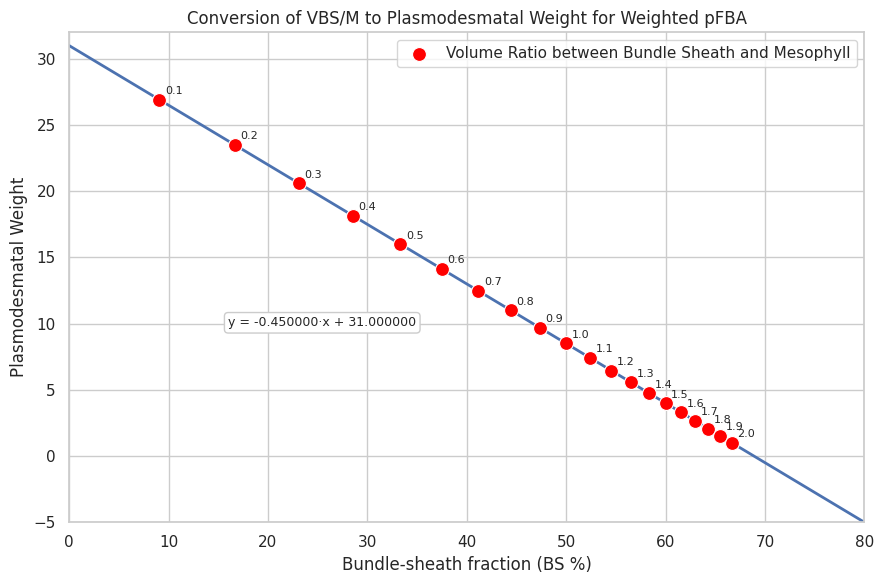

In [3]:
def scale(x, in_min, in_max, out_min, out_max):
    return (x - in_min) / (in_max - in_min) * (out_max - out_min) + out_min

def scale_linear(ratio, out_min, out_max):
    v_bs = ratio / (1 + ratio)
    in_min = 0.5 / (1 + 0.5)
    in_max = 2 / (1 + 2)
    return scale(v_bs, in_min, in_max, out_min, out_max)

# Analytical coefficients
out_min = 16
out_max = 1
in_min = 0.5 / (1 + 0.5)
in_max = 2 / (1 + 2)
A = (out_max - out_min) / (in_max - in_min)
C = out_min - A * in_min
m = A / 100.0
b = C

# Continuous curve
x = np.linspace(0, 100, 501)
v_bs_vals = x / 100
y = A * v_bs_vals + C

# Ratio points
v_ratio_list = np.arange(0.1, 2.01, 0.1)
bs_percents = [ (r/(1+r))*100 for r in v_ratio_list ]
y_points = [ scale_linear(r, out_min=out_min, out_max=out_max) for r in v_ratio_list ]

# --- seaborn plot ---
sns.set(style="whitegrid")
plt.figure(figsize=(9,6))
sns.lineplot(x=x, y=y, linewidth=2, zorder = 1)
sns.scatterplot(x=bs_percents, y=y_points, label="Volume Ratio between Bundle Sheath and Mesophyll", s=100, color='red',  zorder=2)

for xi, yi, r in zip(bs_percents, y_points, v_ratio_list):
    plt.annotate(f"{r:.1f}", (xi, yi),
                 textcoords="offset points", xytext=(4,4), fontsize=8)

plt.xlabel("Bundle-sheath fraction (BS %)")
plt.ylabel("Plasmodesmatal Weight")
plt.title("Conversion of VBS/M to Plasmodesmatal Weight for Weighted pFBA")
plt.ylim(-5, 32)
plt.xlim(0, 80)

eq_text = f"y = {m:.6f}·x + {b:.6f}"
plt.text(0.2, 0.4, eq_text,
         transform=plt.gca().transAxes,
         fontsize=9, bbox=dict(boxstyle='round', fc='white', ec='0.8'))

plt.tight_layout()
plt.show()

## 3. Simulation Functions
Define the core functions for running the simulations, including the weighted pFBA implementation and the specific constraint application for each scenario.

### Weighted pFBA Implementation
Implements a parsimonious Flux Balance Analysis where the cost of flux is weighted by the volume of the compartment or the transport resistance.

In [4]:
"""
Code necessary to run a  weighted pFBA
"""
from itertools import chain
from typing import TYPE_CHECKING, Callable, Dict, List, Optional, Union
from warnings import warn
from optlang.symbolics import Zero
from cobra.core.solution import get_solution
from cobra.util import solver as sutil
if TYPE_CHECKING:
    from optlang.interface import Objective
    from cobra import Model, Reaction, Solution

# Define a function to scale plasmodesmatal exchange reaction weights based on volume ratio
def plasmodesmatal_scaling(v_bs_m):
    x = v_bs_m / (1 + v_bs_m)
    y = - 45 * x + 31   # Linear scaling derived from anatomical data
    return y 

# Define the main function for performing weighted pFBA
def weighted_pfba(
    model: "Model",
    fraction_of_optimum: float = 1.0,  # Fraction of the optimal solution to maintain
    objective: Union[Dict, "Objective", None] = None,  # Optional custom objective
    reactions: Optional[List["Reaction"]] = None,  # List of reactions to include in the solution
    volume_ratio: float = 1.0,  # Ratio of bundle sheath to mesophyll volume
) -> "Solution":
    """
    Perform weighted parsimonious flux balance analysis (pFBA) on a given metabolic model.

    Args:
        model: The metabolic model to analyze.
        fraction_of_optimum: Fraction of the optimal solution to maintain.
        objective: Optional custom objective for the analysis.
        reactions: List of reactions to include in the solution.
        volume_ratio: Ratio of bundle sheath to mesophyll volume.

    Returns:
        A Solution object containing the flux distribution.
    """
    # Use all reactions if no specific reactions are provided
    reactions = (
        model.reactions if reactions is None else model.reactions.get_by_any(reactions)
    )
    with model as m:
        # Add the weighted pFBA objective to the model
        add_weighted_pfba(m, objective=objective, fraction_of_optimum=fraction_of_optimum, volume_ratio=volume_ratio)
        # Optimize the model to find the solution
        m.slim_optimize(error_value=None)
        # Extract the solution for the specified reactions
        solution = get_solution(m, reactions=reactions)
    return solution

# Define a helper function to add the weighted pFBA objective to the model
def add_weighted_pfba(
    model: "Model",
    objective: Union[Dict, "Objective", None] = None,  # Optional custom objective
    fraction_of_optimum: float = 1.0,  # Fraction of the optimal solution to maintain
    volume_ratio: float = 1.0,  # Ratio of bundle sheath to mesophyll volume
) -> None:
    """
    Add a weighted pFBA objective to the given metabolic model.

    Args:
        model: The metabolic model to modify.
        objective: Optional custom objective for the analysis.
        fraction_of_optimum: Fraction of the optimal solution to maintain.
        volume_ratio: Ratio of bundle sheath to mesophyll volume.

    Raises:
        ValueError: If the model already has a weighted pFBA objective.
    """
    # Set the custom objective if provided
    if objective is not None:
        model.objective = objective

    # Normalize the volume ratios for mesophyll and bundle sheath
    VM_Norm = 1 / (1 + volume_ratio)
    VBS_Norm = volume_ratio / (1 + volume_ratio)

    # Check if the model already has a weighted pFBA objective
    if model.solver.objective.name == "_weighted_pfba_objective":
        raise ValueError("The model already has a weighted pFBA objective.")

    # Fix the current objective as a constraint to maintain a fraction of the optimum
    sutil.fix_objective_as_constraint(model, fraction=fraction_of_optimum)

    # Get the forward and reverse variables for all reactions
    reaction_variables = (
        (rxn.forward_variable, rxn.reverse_variable) for rxn in model.reactions
    )
    variables = chain(*reaction_variables)

    # Create a new objective for minimizing the weighted fluxes
    model.objective = model.problem.Objective(
        Zero, direction="min", sloppy=True, name="_weighted_pfba_objective"
    )

    # Initialize a dictionary to store the objective coefficients
    objective_dict = {}

    for v in variables:
        #The new objective coefficient for the mesophyll corresponds to mesophyll volume fraction
        if "[M]" in str(v): 
            objective_dict[v] = VM_Norm
         #The new objective coefficient for the bundle sheath corresponds to bundle sheath  volume fraction
        elif "[B]" in str(v): 
            objective_dict[v] = VBS_Norm
            
        #The new objective coefficient for the plasmodesmata exchange reactions is scaled according to the volume ratio
        elif "[MB]" in str(v):
            objective_dict[v] = plasmodesmatal_scaling(volume_ratio)
            
        else:
            pass
    # Set the new objective coefficients in the model
    model.objective.set_linear_coefficients(objective_dict)

### Simulation Wrapper (`simul`)
Configures the model for a specific set of parameters (Carbon, Nitrogen, Light, Volume Ratio, etc.) and runs the weighted pFBA.

In [5]:
#Function to run the parameter scan
def simul(c4_model, carbon = 20, nitrogen = 1000, light = 1000, volume_ratio = 1,
          biomass_objective = "[M]_Arabidopsis_biomass_tx", BS_PSII = True, Rubisco_Ex = False,
          PC_M = 1, PC_BS = 1, sub = True, Vc_Vo = 3, C4_BS = True, M_RUBISCO=True, leakage = None):
    """
        Simulates the metabolic behavior of a C4 photosynthesis model under various conditions.
        Parameters:
        -----------
        c4_model : cobra.Model
            The metabolic model representing the C4 photosynthesis system.
        carbon : float, optional
            Maximum CO2 uptake rate (default is 20).
        nitrogen : float, optional
            Maximum nitrogen uptake rate (default is 1000).
        light : float, optional
            Maximum light uptake rate (default is 1000).
        volume_ratio : float, optional
            Ratio of bundle sheath (BS) to mesophyll (M) cell volumes (default is 1).
        biomass_objective : str, optional
            The reaction ID for the biomass objective function (default is "[M]_Arabidopsis_biomass_tx").
        BS_PSII : bool, optional
            Whether to enable photosystem II activity in bundle sheath cells (default is True).
        Rubisco_Ex : bool, optional
            Whether to enable Rubisco exchange in bundle sheath cells (default is False).
        PC_M : float, optional
            Proportionality constant for mesophyll photon uptake (default is 1).
        PC_BS : float, optional
            Proportionality constant for bundle sheath photon uptake (default is 1).
        sub : bool, optional
            Whether to enable suberisation in bundle sheath cells, blocking O2 transport (default is True).
        Vc_Vo : float or None, optional
            Rubisco carboxylase/oxygenase ratio. If None, defaults to 100% carboxylation (default is 3).
        C4_BS : bool, optional
            Whether to enable Rubisco activity in bundle sheath cells (default is True).
        M_RUBISCO : bool, optional
            Whether to enable Rubisco activity in mesophyll cells (default is True).
        Returns:
        --------
        pandas.DataFrame
            A DataFrame containing the flux distribution of the model under the specified conditions.
            If the solution is infeasible, the DataFrame will contain zeros for all reactions.
        Raises:
        -------
        Exception
            If an invalid biomass objective equation is provided.
        Notes:
        ------
        - The function modifies the input `c4_model` by adding constraints and adjusting reaction bounds.
        - The function uses a weighted parsimonious flux balance analysis (pFBA) to calculate the flux distribution.
        - The function normalizes systemic uptakes and biomass secretion based on the volume ratio.
    """

    with c4_model:
            # Define volume normalization factors for mesophyll and bundle sheath cells
            VM_Norm = 1 / (1 + volume_ratio)
            VBS_Norm = volume_ratio / (1 + volume_ratio)
            
            # --- Rubisco Carboxylase/Oxygenase Ratio Constraints ---
            # If Vc_Vo is not None, set up constraints for Rubisco carboxylase/oxygenase ratio
            if Vc_Vo != None:
                # Add constraint for mesophyll Rubisco activity
                const = c4_model.problem.Constraint(
                    Vc_Vo * c4_model.reactions.get_by_id("[M]_RXN_961_p").flux_expression - 
                    1 * c4_model.reactions.get_by_id("[M]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p").flux_expression, lb=0, ub=0)
                c4_model.add_cons_vars(const)

                # Add constraint for bundle sheath Rubisco activity
                const = c4_model.problem.Constraint(
                    Vc_Vo * c4_model.reactions.get_by_id("[B]_RXN_961_p").flux_expression - 
                    1 * c4_model.reactions.get_by_id("[B]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p_Ex").flux_expression, lb=0, ub=0)
                c4_model.add_cons_vars(const)
                
                # Update the solver with the new constraints
                c4_model.solver.update()

                # Convert Vc_Vo to percentage for carboxylation
                Vc_Vo = round((Vc_Vo / (Vc_Vo + 1)) * 100, 0)
            else:
                # Default to 100% carboxylation if Vc_Vo is None
                Vc_Vo = 100

            # --- Leakage Constraints ---
            if leakage != None:
                    c4_model.reactions.get_by_id("[MB]_O2_leakage_c").bounds = (-1000, 1000)
                    c4_model.reactions.get_by_id("[MB]_CO2_leakage_c").bounds = (-1000, 0)
                    
                    ## Leakage constraints
                    o2_leak = c4_model.reactions.get_by_id("[MB]_O2_leakage_c")
                    psii_b = c4_model.reactions.get_by_id("[B]_PSII_RXN_p")

                    cons = c4_model.problem.Constraint(
                        o2_leak.flux_expression - leakage * psii_b.flux_expression,
                        ub=0
                    )

                    c4_model.add_cons_vars(cons)
                    
                    #Canonical Decarboxylation reactions
                    CO2_leak = c4_model.reactions.get_by_id("[MB]_CO2_leakage_c")
                    Gly_Decarbox = c4_model.reactions.get_by_id("[B]_GCVMULTI_RXN_m")
                    PEP_CK = c4_model.reactions.get_by_id("[B]_PEPCARBOXYKIN_RXN_c")
                    NAD_ME = c4_model.reactions.get_by_id("[B]_1_PERIOD_1_PERIOD_1_PERIOD_39_RXN_m")
                    NADP_ME = c4_model.reactions.get_by_id("[B]_MALIC_NADP_RXN_p")

                    # ---------- Plastid (_p) decarboxylations (BS) ----------
                    DIAMINOPIMDECARB_p   = c4_model.reactions.get_by_id("[B]_DIAMINOPIMDECARB_RXN_p")
                    IGPSYN_p             = c4_model.reactions.get_by_id("[B]_IGPSYN_RXN_p")
                    RXN_9652_p           = c4_model.reactions.get_by_id("[B]_RXN_9652_p")
                    ACETOOHBUTSYN_p      = c4_model.reactions.get_by_id("[B]_ACETOOHBUTSYN_RXN_p")
                    RXN_9650_p           = c4_model.reactions.get_by_id("[B]_RXN_9650_p")
                    RXN_5682_p           = c4_model.reactions.get_by_id("[B]_RXN_5682_p")
                    KASIII_2_3_1_180_p   = c4_model.reactions.get_by_id("[B]_2_PERIOD_3_PERIOD_1_PERIOD_180_RXN_p")
                    RXN_9654_p           = c4_model.reactions.get_by_id("[B]_RXN_9654_p")
                    PYRUVDEH_p           = c4_model.reactions.get_by_id("[B]_PYRUVDEH_RXN_p")        # plastid PDH
                    RXN_9653_p           = c4_model.reactions.get_by_id("[B]_RXN_9653_p")
                    RXN_7800_p           = c4_model.reactions.get_by_id("[B]_RXN_7800_p")
                    RXN_9651_p           = c4_model.reactions.get_by_id("[B]_RXN_9651_p")
                    RXN_9648_p           = c4_model.reactions.get_by_id("[B]_RXN_9648_p")
                    ACETOLACTSYN_p       = c4_model.reactions.get_by_id("[B]_ACETOLACTSYN_RXN_p")

                    # ---------- Cytosolic (_c) decarboxylations ----------
                    ISOCITDEH_c          = c4_model.reactions.get_by_id("[B]_ISOCITDEH_RXN_c")

                    # ---------- Mitochondrial (_m) decarboxylations ----------
                    PYRUVDEH_m           = c4_model.reactions.get_by_id("[B]_PYRUVDEH_RXN_m")     # mito PDH


                    const = c4_model.problem.Constraint(
                        CO2_leak.flux_expression + VBS_Norm * leakage* (ISOCITDEH_c.flux_expression + ACETOLACTSYN_p.flux_expression + RXN_9648_p.flux_expression + 
                                                                         RXN_9651_p.flux_expression + RXN_7800_p.flux_expression + RXN_9653_p.flux_expression +
                                                                         PYRUVDEH_p.flux_expression + RXN_9654_p.flux_expression + KASIII_2_3_1_180_p.flux_expression + RXN_5682_p.flux_expression + 
                                                                         RXN_9650_p.flux_expression + ACETOOHBUTSYN_p.flux_expression + RXN_9652_p.flux_expression + 
                                                                         IGPSYN_p.flux_expression + DIAMINOPIMDECARB_p.flux_expression + PYRUVDEH_m.flux_expression +
                    Gly_Decarbox.flux_expression + PEP_CK.flux_expression + NAD_ME.flux_expression + NADP_ME.flux_expression),
                        lb=0, ub=0
                    )
                    c4_model.add_cons_vars(const)
            else:
                c4_model.reactions.get_by_id("[MB]_O2_leakage_c").bounds = (0, 0)
                c4_model.reactions.get_by_id("[MB]_CO2_leakage_c").bounds = (0, 0)

            # --- Biomass Objective Configuration ---
            # Set the biomass objective equation and block other biomass-related reactions
            c4_model.reactions.get_by_id("[M]_AraCore_Biomass_tx").bounds = (0, 0)
            c4_model.reactions.get_by_id("[B]_AraCore_Biomass_tx").bounds = (0, 0)
            c4_model.reactions.get_by_id("[M]_Phloem_output_tx").bounds = (0, 0)
            c4_model.reactions.get_by_id("[B]_Phloem_output_tx").bounds = (0, 0)

            # Configure the biomass objective 
            if biomass_objective == "[M]_Arabidopsis_biomass_tx":
                c4_model.reactions.get_by_id("[M]_Arabidopsis_biomass_tx").bounds = (0, 1000)
                c4_model.reactions.get_by_id("[B]_Arabidopsis_biomass_tx").bounds = (0, 0)
            
            else:
                raise Exception("Please insert a valid biomass equation")
            
            # Set the objective function to the selected biomass reaction
            c4_model.objective = c4_model.reactions.get_by_id(biomass_objective)
            
            # --- Photosynthetic Constraints ---
            # Enable or disable photosystem II activity in bundle sheath cells
            if BS_PSII == True:
                set_bounds('[B]_PSII_RXN_p', (0, 999999), c4_model)
            else:
                set_bounds('[B]_PSII_RXN_p', (0, 0), c4_model)

            # Enable or disable Rubisco activity in bundle sheath cells
            if C4_BS == True:
                set_bounds('[B]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p', (0, 1000), c4_model)
            else:
                set_bounds('[B]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p', (0, 0), c4_model)

            # Enable or disable Rubisco activity in mesophyll cells
            if M_RUBISCO == True:
                set_bounds('[M]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p', (0, 1000), c4_model)
            else:
                set_bounds('[M]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p', (0, 0), c4_model)

            # --- Suberisation (Transport Constraints) ---
            # Enable or disable suberisation in bundle sheath cells
            if sub == True:
                # Block O2 transport between cell types
                set_bounds("[MB]_OXYGEN_MOLECULE_c", (0, 0), c4_model)
                set_bounds("[MB]_SUPER_OXIDE_c", (0, 0), c4_model)
                set_bounds("[MB]_CO2_c", (0, 0), c4_model)

            else:
                # Allow O2 transport between cell types
                set_bounds("[MB]_OXYGEN_MOLECULE_c", (-999999, 999999), c4_model)
                set_bounds("[MB]_SUPER_OXIDE_c", (-999999, 999999), c4_model)
                set_bounds("[MB]_CO2_c", (-999999, 999999), c4_model)
       
            # Enable or disable Rubisco exchange in bundle sheath cells
            if Rubisco_Ex == True:
                set_bounds("[B]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p_Ex", (0, 1000), c4_model)
            else:
                set_bounds("[B]_RIBULOSE_BISPHOSPHATE_CARBOXYLASE_RXN_p_Ex", (0, 0), c4_model)

            # --- Medium and Uptake Constraints ---
            # Set maximum CO2 and nitrogen uptake rates in the medium
            medium = c4_model.medium
            medium["[M]_CO2_tx"] = carbon  # CO2 uptake constraint
            medium["[B]_Nitrate_tx"] = nitrogen  # Nitrogen uptake constraint
            medium["[B]_O2_tx"] = 0  # Block O2 uptake in bundle sheath cells
            medium["[B]_CO2_tx"] = 0  # Block CO2 uptake in bundle sheath cells
            c4_model.medium = medium
            
            # Normalize exchange reactions between mesophyll and bundle sheath cells
            for reaction in c4_model.reactions:
                if reaction.id[0:4] == "[MB]":
                    dict = {reaction.products[0]: -(1 / VBS_Norm)}
                    reaction.subtract_metabolites(dict, combine=False)
                    dict = {reaction.reactants[0]: (1 / VM_Norm)}
                    reaction.subtract_metabolites(dict, combine=False)
            
            # Set light uptake constraints for mesophyll and bundle sheath cells
            set_bounds("[M]_Photon_tx", (0, light * PC_M), c4_model)
            set_bounds("[B]_Photon_tx", (0, light * PC_BS), c4_model)
            
            # --- Blocking Specific Transporters ---
            #Block Mannitol Transport
            set_bounds("[MB]_MANNITOL_1P_c", (0, 0), c4_model)
            set_bounds("[MB]_MANNITOL_c", (0, 0), c4_model)

            #Block Excchange of Alternative Triose Phosphates and Phosphoglycollate
            set_bounds("[MB]_DIHYDROXY_ACETONE_PHOSPHATE_c", (0, 0), c4_model)
            set_bounds("[MB]_2_PG_c", (0, 0), c4_model)
            set_bounds("[MB]_MANNOSE_c", (0, 0), c4_model)
            set_bounds("[MB]_MANNOSE_6P_c", (0, 0), c4_model)
            set_bounds("[MB]_FUM_c", (0, 0), c4_model)

            #Block Glycollate transport
            set_bounds("[MB]_GLYCOLLATE_c", (0, 0), c4_model)
            set_bounds("[MB]_2_KETOGLUTARATE_c", (0, 0), c4_model)

            #Block Phosphate transport
            set_bounds("[MB]_Pi_c", (-1000, 1000), c4_model)
            set_bounds("[MB]_aPi_c", (-1000, 1000), c4_model)

            #Block Proton Uptake 
            set_bounds("[B]_H_tx", (0, 0), c4_model)
            set_bounds("[M]_H_tx", (0, 0), c4_model)

            #Block glucose 1 P and Heteroglycan Transport
            set_bounds("[MB]_GLC_1_P_c", (0, 0), c4_model)
            set_bounds("[MB]_Heteroglycans_c", (0, 0), c4_model)


            # --- Normalization of Systemic Uptakes ---
            # Normalize systemic uptakes into mesophyll and bundle sheath cells
            M_Uptakes_List = ['[M]_Ca_tx', '[M]_H2O_tx', '[M]_CO2_tx', '[M]_O2_tx', '[M]_Pi_tx', 
                              '[M]_Mg_tx', '[M]_Nitrate_tx', '[M]_SO4_tx', '[M]_NH4_tx', '[M]_K_tx', '[M]_unlProtHYPO_c']
            
            BS_Uptakes_List = ['[B]_Ca_tx', '[B]_H2O_tx', '[B]_CO2_tx', '[B]_O2_tx', '[B]_Pi_tx', 
                              '[B]_Mg_tx', '[B]_Nitrate_tx', '[B]_SO4_tx', '[B]_NH4_tx', '[B]_K_tx', '[B]_unlProtHYPO_c']
        
            for reaction in c4_model.reactions:
                if reaction.id in M_Uptakes_List:
                    dict = {reaction.products[0]: -(1 / VM_Norm)}
                    reaction.subtract_metabolites(dict, combine=False)
                elif reaction.id in BS_Uptakes_List:
                    dict = {reaction.products[0]: -(1 / VBS_Norm)}
                    reaction.subtract_metabolites(dict, combine=False)

            # Normalize biomass secretion for mesophyll cells
            M_biomass_List = ["[M]_Arabidopsis_biomass_tx", "[M]_Maize_biomass_tx"]

            dict_comb = {}

            for reaction in c4_model.reactions:
                if reaction.id in M_biomass_List:
                    for index in range(len(reaction.reactants)):
                        dictionary = {reaction.reactants[index]: -((reaction.get_coefficient(reaction.reactants[index]) / VM_Norm))}
                        dict_comb.update(dictionary)
                    reaction.subtract_metabolites(dict_comb, combine=False)

            # --- Execution ---
            # Run weighted parsimonious flux balance analysis (pFBA)
            try:
                solution = weighted_pfba(model=c4_model, volume_ratio=volume_ratio)  
                solution_frame = solution.to_frame()
                solution_frame.rename(columns={"fluxes": "{}_{}_{}_{}_{}_{}_{}".format(light, volume_ratio, PC_M, PC_BS, Vc_Vo, carbon, nitrogen)}, inplace=True)
            
            # Handle unfeasible flux solutions
            except:
                solution = {"{}_{}_{}_{}_{}_{}_{}".format(light, volume_ratio, PC_M, PC_BS, Vc_Vo, carbon, nitrogen): [0] * len(c4_model.reactions)}
                
                # Unfeasible solutions will have 0s in place of parameters
                reaction_index = [reaction.id for reaction in c4_model.reactions]
                solution_frame = pd.DataFrame(solution, index=reaction_index)
                
            # Return the solution as a DataFrame
            return solution_frame.iloc[:, 0].to_frame()

## 4. Parameter Scan Execution
Define the parameter ranges and the multiprocessing function to run simulations in parallel.

In [6]:
#List of parameters for parameter scan

#List of V_BS/M ratios
v_ratio_list = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1, 1.1, 1.2, 1.3, 1.4, 1.5, 1.6, 1.7, 1.8, 1.9, 2]

#List of PPFDs (light intensities)
light_list = [1000]

#List of A (maximum carbon assimilation)
carbon_list = [20]

#List of maximum nitrate assimilation
nitrogen_list = [1000]

#List of photorespiratory ratios ((Vc/(Vc+Vo)) * 100)
Photoresp_ratio_list = [50, 55, 60 ,65, 70, 75, 80, 85, 90, 95, None]

#List of mesophyll photosynthetic capacity %s
PC_M_list = [1]

#List of bundle sheath photosynthetic capacity %s
PC_BS_list = [1]

def model_scan(model, carbon_list, nitrogen_list, light_list, v_ratio_list, PC_M, PC_BS, Photoresp_ratio_list,
               biomass_equation, PSII = True, BS_Rubisco = False, csv_filename = "20_PSII.csv", suberisation = True, BS_C4 = True, Mesophyll_Rubisco = True,
               leakage = None):
    """
    Perform a parameter scan for a given C4 photosynthesis model using multiprocessing.
    This function generates combinations of input parameters, runs simulations in parallel
    using these combinations, and aggregates the results into a single DataFrame.
    Args:
        model (object): The C4 photosynthesis model to be simulated.
        carbon_list (list): List of carbon uptake values to be tested.
        nitrogen_list (list): List of nitrogen uptake values to be tested.
        light_list (list): List of light intensity values to be tested.
        v_ratio_list (list): List of volume ratio values to be tested.
        PC_M (list): List of mesophyll phosphoenolpyruvate carboxylase (PEPC) values.
        PC_BS (list): List of bundle sheath phosphoenolpyruvate carboxylase (PEPC) values.
        Photoresp_ratio_list (list): List of photorespiratory ratios (as percentages) to be tested.
        biomass_equation (callable): String representing the biomass objective.
        PSII (bool, optional): Whether PSII is active in the bundle sheath. Defaults to True.
        BS_Rubisco (bool, optional): Whether Rubisco is exclusively in the bundle sheath. Defaults to False.
        csv_filename (str, optional): Filename for saving results (not used in this function). Defaults to "20_PSII.csv".
        suberisation (bool, optional): Whether suberisation is considered in the model. Defaults to True.
        BS_C4 (bool, optional): Whether C4 metabolism is active in the bundle sheath. Defaults to True.
        Mesophyll_Rubisco (bool, optional): Whether Rubisco is active in the mesophyll. Defaults to True.
    Returns:
        pd.DataFrame: A DataFrame containing the aggregated results of the parameter scan.
    Notes:
        - The function uses all available CPU cores for parallel processing.
        - The photorespiratory ratios are converted from percentages to Vc:Vo ratios internally.
        - The `simul` function is used to run the simulations.
    """
    
    #Converting photorespiratory ratio from percentage to x:1 (Vc:Vo) ratios
    photo_ratio = []
    for ratio in Photoresp_ratio_list:
        if ratio != None:
            value = -(ratio/(ratio-100))
            photo_ratio.append(value)
        else:
            photo_ratio.append(ratio)

    appended_dataframes = []
    
    global run_simulation
    
    def run_simulation(parameters):

    #Calling existing simulation function with the given parameters
        return simul(c4_model = model, carbon = parameters[5], nitrogen = parameters[6], light = parameters[1], 
                    volume_ratio = parameters[0], biomass_objective = biomass_equation, BS_PSII = PSII, Rubisco_Ex = BS_Rubisco,
                    PC_M = parameters[2], PC_BS = parameters[3], sub=suberisation, Vc_Vo= parameters[4], C4_BS=BS_C4, M_RUBISCO = Mesophyll_Rubisco, leakage=leakage)

    # Create a list of parameter combinations
    all_parameters = [(v_ratio, light_value, PC_M_value, PC_BS_value, resp_ratio, c_uptake, n_uptake) for v_ratio in v_ratio_list for light_value in light_list for PC_M_value in PC_M for PC_BS_value in PC_BS for resp_ratio in photo_ratio for c_uptake in carbon_list for n_uptake in nitrogen_list]

    appended_dataframes = []

    if __name__ == '__main__':
        # Number of processes to use - using all CPUs
        num_processes = multiprocessing.cpu_count()

        # Create a pool of worker processes
        with multiprocessing.Pool(processes=num_processes) as pool:
            # Use map to distribute the parameter combinations to worker processes
            results = pool.map(run_simulation, all_parameters)
            appended_dataframes.extend(results)

    #Merging the resulting Datasets
    parameter_scan_df = pd.concat(appended_dataframes, axis=1)

    #Checking Dataframes for consistency
    return parameter_scan_df

### Scenario 1: C3 Metabolism (Unsuberised)
Simulate C3 metabolism where Rubisco is active in the Mesophyll, no C4 cycle in BS, and no suberin barrier.

In [7]:
data = model_scan(model=c4_model, carbon_list = carbon_list, nitrogen_list = nitrogen_list, 
                                light_list=light_list, v_ratio_list = v_ratio_list, PC_M=PC_M_list, PC_BS=PC_BS_list,
                                biomass_equation="[M]_Arabidopsis_biomass_tx",
                                PSII = True,  BS_Rubisco = False, Mesophyll_Rubisco = True,
                                suberisation = False, Photoresp_ratio_list=Photoresp_ratio_list, BS_C4 = False, leakage = None)

data.to_csv("../Datasets/Scan_C3_Weighted.csv")

### Scenario 2: C3 Metabolism (Suberised)
Simulate C3 metabolism with a suberin barrier (hypothetical scenario to test diffusion constraints).

In [8]:
data = model_scan(model=c4_model, carbon_list = carbon_list, nitrogen_list = nitrogen_list, 
                                light_list=light_list, v_ratio_list = v_ratio_list, PC_M=PC_M_list, PC_BS=PC_BS_list,
                                biomass_equation="[M]_Arabidopsis_biomass_tx",
                                PSII = True,  BS_Rubisco = False, Mesophyll_Rubisco = True,
                                suberisation = True, Photoresp_ratio_list=Photoresp_ratio_list, BS_C4 = False, leakage = None)

data.to_csv("../Datasets/Scan_C3_Weighted_Suberised.csv")

### Scenario 3: C4 Metabolism (Unsuberised)
Simulate C4 metabolism (Rubisco in BS, C4 cycle active) without a suberin barrier.

In [9]:
data = model_scan(model=c4_model, carbon_list = carbon_list, nitrogen_list = nitrogen_list, 
                                light_list=light_list, v_ratio_list = v_ratio_list, PC_M=PC_M_list, PC_BS=PC_BS_list,
                                biomass_equation="[M]_Arabidopsis_biomass_tx",
                                PSII = True,  BS_Rubisco = False, Mesophyll_Rubisco = False,
                                suberisation = False, Photoresp_ratio_list=Photoresp_ratio_list, BS_C4 = True, leakage = None)

data.to_csv("../Datasets/Scan_C4_Weighted.csv")

### Scenario 4: C4 Metabolism (Suberised)
Simulate standard C4 metabolism with a suberin barrier preventing gas leakage.

In [10]:
data = model_scan(model=c4_model, carbon_list = carbon_list, nitrogen_list = nitrogen_list, 
                                light_list=light_list, v_ratio_list = v_ratio_list, PC_M=PC_M_list, PC_BS=PC_BS_list,
                                biomass_equation="[M]_Arabidopsis_biomass_tx",
                                PSII = True,  BS_Rubisco = False, Mesophyll_Rubisco = False,
                                suberisation = True, Photoresp_ratio_list=Photoresp_ratio_list, BS_C4 = True, leakage = None)

data.to_csv("../Datasets/Scan_C4_Weighted_Suberised.csv")

### Scenario 5: Variable Metabolism (Unsuberised)
Simulate a scenario where Rubisco is active in both Mesophyll and Bundle Sheath (C3-C4 intermediate-like) without suberin.

In [11]:
data = model_scan(model=c4_model, carbon_list = carbon_list, nitrogen_list = nitrogen_list, 
                                light_list=light_list, v_ratio_list = v_ratio_list, PC_M=PC_M_list, PC_BS=PC_BS_list,
                                biomass_equation="[M]_Arabidopsis_biomass_tx",
                                PSII = True,  BS_Rubisco = True, Mesophyll_Rubisco = True,
                                suberisation = False, Photoresp_ratio_list=Photoresp_ratio_list, BS_C4 = True, leakage = None)

data.to_csv("../Datasets/Scan_Variable_Weighted.csv")

### Scenario 6: Variable Metabolism (Suberised)
Simulate a scenario where Rubisco is active in both cells with a suberin barrier.

In [12]:
data = model_scan(model=c4_model, carbon_list = carbon_list, nitrogen_list = nitrogen_list, 
                                light_list=light_list, v_ratio_list = v_ratio_list, PC_M=PC_M_list, PC_BS=PC_BS_list,
                                biomass_equation="[M]_Arabidopsis_biomass_tx",
                                PSII = True,  BS_Rubisco = True, Mesophyll_Rubisco = True,
                                suberisation = True, Photoresp_ratio_list=Photoresp_ratio_list, BS_C4 = True, leakage = None)

data.to_csv("../Datasets/Scan_Variable_Weighted_Suberised.csv")

In [13]:
end = time.time()

print("The analysis lasted {} minutes".format((end-start)/60))

The analysis lasted 0.37189288934071857 minutes
